# Airbnb Madrid — Exploración y limpieza

Dataset: [Inside Airbnb](http://insideairbnb.com/), Madrid (scrape de junio de 2026).

| Archivo | Contenido | Filas |
|---|---|---|
| `listings.csv` | Resumen de anuncios | ~22,8k |
| `listings_1.csv` | Detalle de anuncios (90 columnas) | ~22,7k |
| `calendar.csv` | Disponibilidad por anuncio y día | ~8,3M |
| `reviews.csv` | Reseñas (anuncio + fecha) | ~1,4M |
| `reviews_1.csv` | Reseñas (texto completo) | ~1,4M |
| `neighbourhoods.csv` / `.geojson` | Catálogo y geometría de barrios | 128 |

Carga, detección de problemas, limpieza y exportación a Parquet en `data/processed/`.

In [1]:
import json
import numpy as np
import pandas as pd
import missingno as msno
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 160)

DATA = '../data'
OUT = '../data/processed'
import os
os.makedirs(OUT, exist_ok=True)

## 1. Carga de datos

Tipos explícitos en la carga para no reinferirlos ni agotar la RAM con `calendar.csv` (8,3M filas).

In [2]:
listings = pd.read_csv(f'{DATA}/listings.csv')
listings_full = pd.read_csv(f'{DATA}/listings_1.csv', low_memory=False)
neighbourhoods = pd.read_csv(f'{DATA}/neighbourhoods.csv')

with open(f'{DATA}/neighbourhoods.geojson', encoding='utf-8') as f:
    geo = json.load(f)

print('listings:', listings.shape)
print('listings_full:', listings_full.shape)
print('neighbourhoods:', neighbourhoods.shape)
print('geojson features:', len(geo['features']))

listings: (22835, 19)
listings_full: (22708, 90)
neighbourhoods: (128, 2)
geojson features: 128


In [3]:
reviews = pd.read_csv(f'{DATA}/reviews.csv', parse_dates=['date'])
reviews_full = pd.read_csv(f'{DATA}/reviews_1.csv', parse_dates=['date'])

print('reviews:', reviews.shape)
print('reviews_full:', reviews_full.shape)

reviews: (1419360, 2)
reviews_full: (1419360, 6)


In [4]:
# calendar.csv es el archivo más pesado (286MB / 8.3M filas): usamos dtypes compactos
# y un converter para 'available' (t/f) en vez de dejar que pandas infiera todo como object.
calendar = pd.read_csv(
    f'{DATA}/calendar.csv',
    parse_dates=['date'],
    dtype={'listing_id': 'int64', 'minimum_nights': 'Int32', 'maximum_nights': 'Int32'},
    converters={'available': lambda x: x == 't'},
)
print('calendar:', calendar.shape)
print(f"memoria: {calendar.memory_usage(deep=True).sum()/1e6:.1f} MB")

calendar: (8334782, 5)
memoria: 225.0 MB


## 2. Inspección general

In [5]:
listings.info()

<class 'pandas.DataFrame'>
RangeIndex: 22835 entries, 0 to 22834
Data columns (total 19 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              22835 non-null  int64  
 1   name                            22835 non-null  str    
 2   host_id                         22708 non-null  float64
 3   host_profile_id                 22556 non-null  float64
 4   host_name                       22556 non-null  str    
 5   neighbourhood_group             22835 non-null  str    
 6   neighbourhood                   22835 non-null  str    
 7   latitude                        22835 non-null  float64
 8   longitude                       22835 non-null  float64
 9   room_type                       22835 non-null  str    
 10  price                           19297 non-null  float64
 11  minimum_nights                  22833 non-null  float64
 12  number_of_reviews               22835 non-n

In [6]:
listings.head()

,id,name,host_id,host_profile_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,license
0,1008521039996399925,Alojamiento tranquilo,509530871.0,1.470291e+18,Sandra,Carabanchel,Opañel,40.387990,-3.72470,Private room,42.0,1.0,0,NaN,NaN,1.0,268,0,NaN
1,887679074200493161,Hermoso para disfrutar Madrid,425181129.0,1.469928e+18,Felix,Puente de Vallecas,Palomeras Sureste,40.385482,-3.64084,Entire home/apt,210.0,1.0,1,2023-05-14,0.03,1.0,364,0,NaN
2,1517952008444895376,Standard Queen,NaN,NaN,NaN,Moncloa - Aravaca,Argüelles,40.420580,-3.71615,Private room,NaN,1.0,2,2026-01-08,0.34,NaN,43,2,NaN
3,21376743,"Bright & comfortable, Malasana Madrid",43556711.0,1.465647e+18,Anthony,Centro,Universidad,40.422940,-3.70374,Entire home/apt,NaN,3.0,4,2018-01-18,0.04,1.0,0,0,NaN
4,1546256895864909953,"H10 Puerta de Alcalá 4 Sup, Classic Room",726634087.0,NaN,NaN,Salamanca,Recoletos,40.422150,-3.68120,Private room,NaN,1.0,1,2026-03-01,0.24,7.0,0,1,NaN


In [7]:
listings_full[['id','price','bathrooms','bathrooms_text','bedrooms','beds','room_type','property_type']].head()

,id,price,bathrooms,bathrooms_text,bedrooms,beds,room_type,property_type
0,1008521039996399925,$42.00,1.0,1 bath,NaN,1.0,Private room,Private room in home
1,887679074200493161,$209.98,1.0,1 bath,1.0,1.0,Entire home/apt,Entire rental unit
2,21376743,NaN,NaN,1 bath,1.0,NaN,Entire home/apt,Entire rental unit
3,1546256895864909953,NaN,NaN,1 private bath,NaN,NaN,Private room,Room in hotel
4,1542083092059647802,$259.09,NaN,1 private bath,NaN,NaN,Private room,Room in hotel


In [8]:
calendar.head()

,listing_id,date,available,minimum_nights,maximum_nights
0,21853,2026-06-20,False,4,40
1,21853,2026-06-21,False,4,40
2,21853,2026-06-22,False,4,40
3,21853,2026-06-23,False,4,40
4,21853,2026-06-24,False,4,40


## 3. Duplicados

Filas exactas y duplicados por clave lógica: `id` en listings, id de reseña en reviews, `(listing_id, date)` en calendar.

In [9]:
print('listings — filas duplicadas:', listings.duplicated().sum())
print('listings — ids duplicados:', listings.id.duplicated().sum())
print('listings_full — ids duplicados:', listings_full.id.duplicated().sum())
print()
print('reviews — filas duplicadas:', reviews.duplicated().sum())
print('reviews_full — ids de reseña duplicados:', reviews_full.id.duplicated().sum())
print()
print('calendar — combinaciones (listing_id, date) duplicadas:', calendar.duplicated(subset=['listing_id','date']).sum())

listings — filas duplicadas: 0
listings — ids duplicados: 0
listings_full — ids duplicados: 0

reviews — filas duplicadas: 11070


reviews_full — ids de reseña duplicados:

 0



calendar — combinaciones (listing_id, date) duplicadas: 0


## 4. Valores faltantes

% de nulos por columna. Las columnas 100% vacías de `listings_full` se descartan.

In [10]:
miss_listings = listings.isna().mean().sort_values(ascending=False) * 100
miss_listings[miss_listings > 0]

license                           35.835340
reviews_per_month                 16.334574
last_review                       16.334574
price                             15.493760
host_name                          1.221809
host_profile_id                    1.221809
host_id                            0.556164
calculated_host_listings_count     0.556164
minimum_nights                     0.008758
dtype: float64

In [11]:
miss_full = listings_full.isna().mean().sort_values(ascending=False) * 100
miss_full[miss_full > 0].head(25)

neighborhood_overview          100.000000
host_since                     100.000000
host_response_time             100.000000
host_thumbnail_url             100.000000
host_acceptance_rate           100.000000
host_response_rate             100.000000
host_verifications             100.000000
neighbourhood                  100.000000
host_total_listings_count      100.000000
host_neighbourhood             100.000000
calendar_updated               100.000000
instant_bookable               100.000000
host_about                      48.357407
license                         35.476484
host_location                   32.961952
bedrooms                        25.184957
bathrooms                       23.802184
beds                            20.010569
review_scores_value             16.373084
review_scores_location          16.368681
review_scores_accuracy          16.364277
review_scores_communication     16.364277
review_scores_checkin           16.364277
review_scores_cleanliness       16

In [12]:
cols_100_pct_nulas = miss_full[miss_full == 100].index.tolist()
print(f'{len(cols_100_pct_nulas)} columnas 100% vacías en listings_full:')
cols_100_pct_nulas

12 columnas 100% vacías en listings_full:


['neighborhood_overview',
 'host_since',
 'host_response_time',
 'host_thumbnail_url',
 'host_acceptance_rate',
 'host_response_rate',
 'host_verifications',
 'neighbourhood',
 'host_total_listings_count',
 'host_neighbourhood',
 'calendar_updated',
 'instant_bookable']

C:\Users\oppen\AppData\Local\Temp\ipykernel_18420\283408103.py:2: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


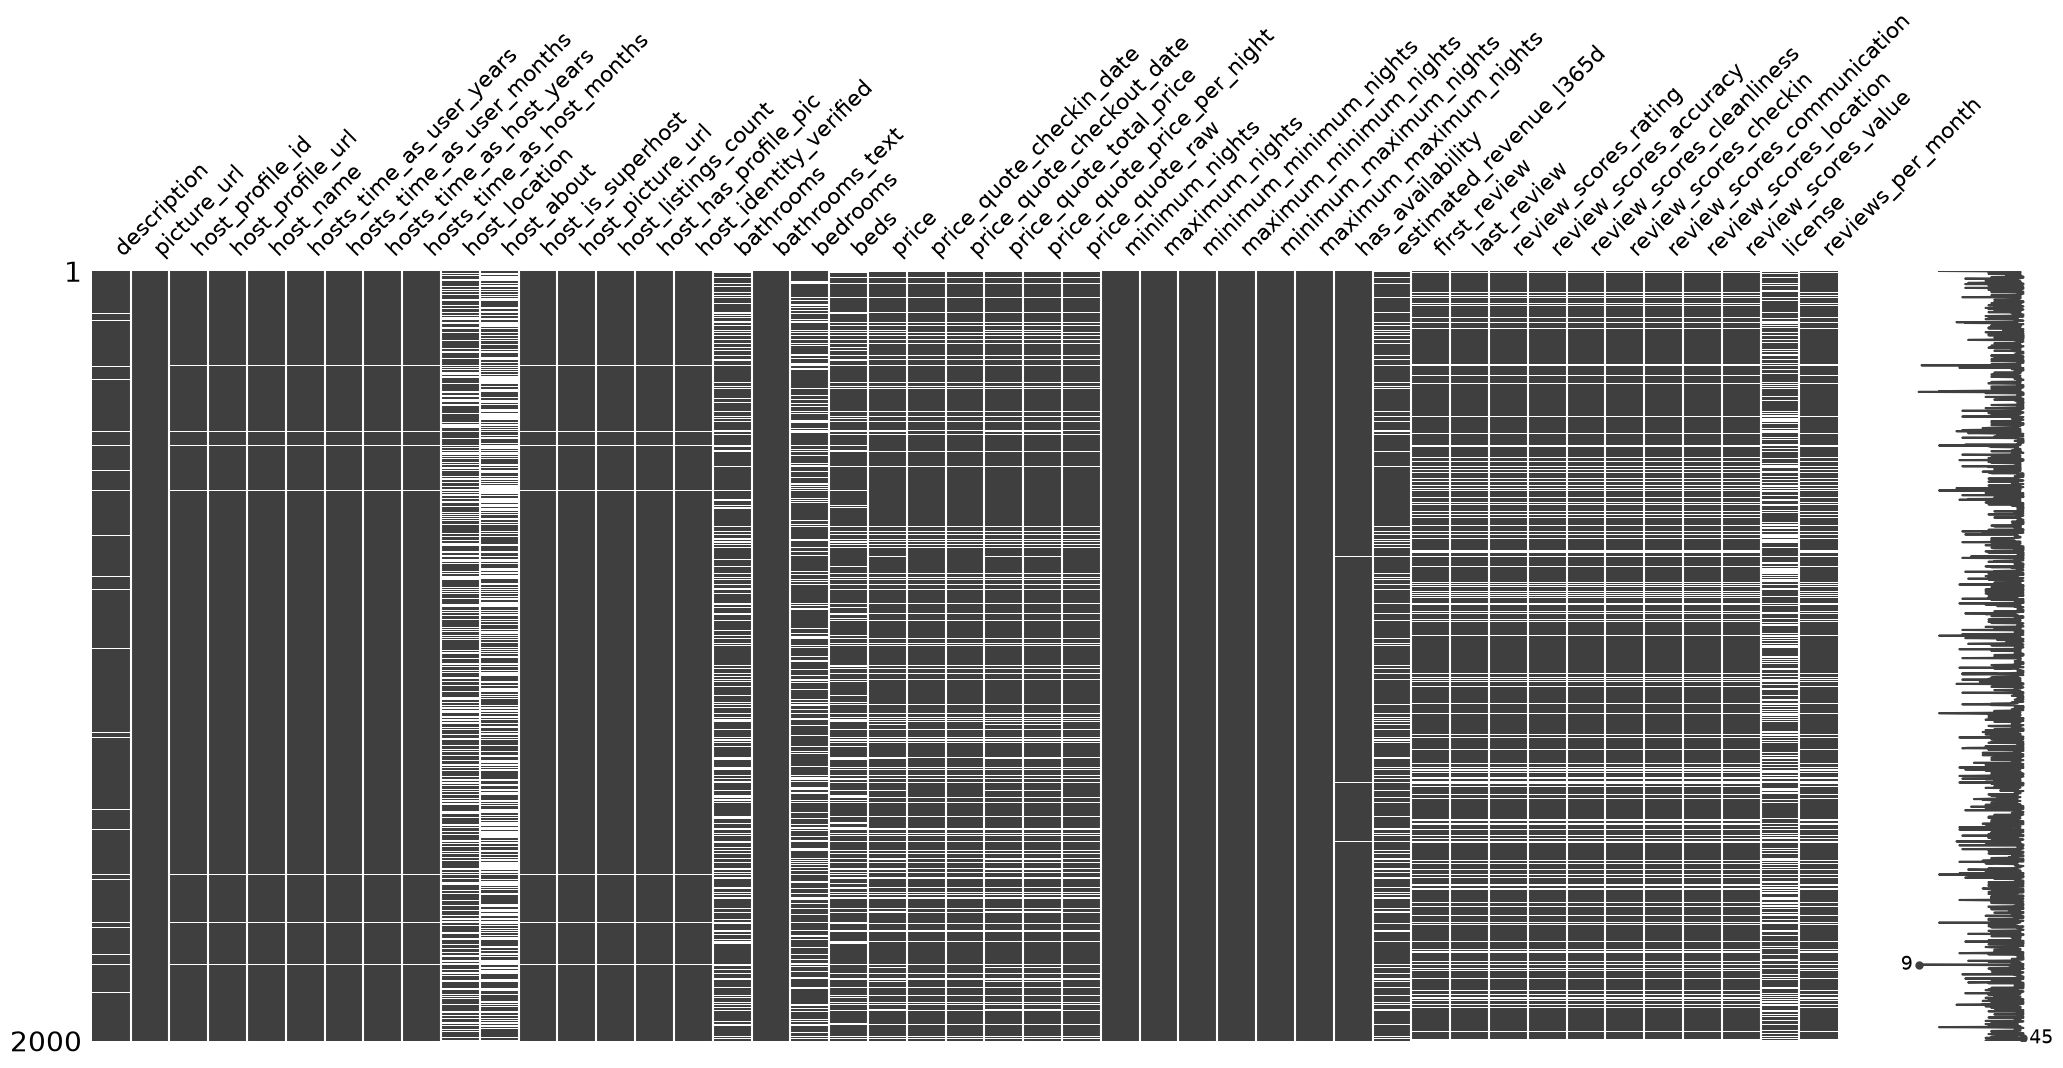

In [13]:
msno.matrix(listings_full[[c for c in listings_full.columns if miss_full.get(c, 0) > 0 and miss_full.get(c, 0) < 100]].sample(2000, random_state=0))
plt.tight_layout()
plt.show()

Tratamiento por tipo de nulo:

- `license`, `host_about`, `host_location`: ausencia real → se deja NaN.
- `last_review`, `reviews_per_month`, `first_review`, `review_scores_*`: nulos estructurales (sin reseñas).
- `price` (~15,5%): se intenta recuperar cruzando `listings` con `listings_full`.
- `bedrooms` / `beds` / `bathrooms` (20-25%): mediana por `room_type`, o parseo de `bathrooms_text`.

In [14]:
sin_reviews = listings_full[listings_full.number_of_reviews == 0]
print('anuncios sin reseñas:', len(sin_reviews))
print('de esos, con last_review nulo:', sin_reviews.last_review.isna().sum())
print('de esos, con reviews_per_month nulo:', sin_reviews.reviews_per_month.isna().sum())

anuncios sin reseñas: 3715
de esos, con last_review nulo: 3715
de esos, con reviews_per_month nulo: 3715


## 5. Datos corruptos e inconsistentes

Se comprueban: coordenadas fuera de Madrid, precios nulos o extremos, `minimum_nights` con
placeholder (1125), barrios ausentes del catálogo y formato texto de `price` (`"$1,234.56"`).

In [15]:
# 5.1 — coordenadas: Madrid cae aprox. en lat 40.31–40.56, lon -3.83 a -3.52
fuera_de_rango = listings[~listings.latitude.between(40.30, 40.60) | ~listings.longitude.between(-3.90, -3.50)]
print('coordenadas fuera de rango esperado:', len(fuera_de_rango))
print('lat min/max:', listings.latitude.min(), listings.latitude.max())
print('lon min/max:', listings.longitude.min(), listings.longitude.max())

coordenadas fuera de rango esperado: 0
lat min/max: 40.33189 40.53553
lon min/max: -3.83206 -3.5459040932605648


In [16]:
# 5.2 — barrios no catalogados
bad_neigh = set(listings.neighbourhood) - set(neighbourhoods.neighbourhood)
bad_group = set(listings.neighbourhood_group) - set(neighbourhoods.neighbourhood_group)
print('neighbourhood sin catalogar:', bad_neigh)
print('neighbourhood_group sin catalogar:', bad_group)

neighbourhood sin catalogar: set()
neighbourhood_group sin catalogar: set()


In [17]:
# 5.3 — minimum_nights con placeholder de "bloqueado" (1125 noches = ~3 años)
placeholder = listings[listings.minimum_nights >= 365]
print('anuncios con minimum_nights >= 365:', len(placeholder))
placeholder[['id', 'name', 'minimum_nights']]

anuncios con minimum_nights >= 365: 23


,id,name,minimum_nights
2530,774773851284478554,Casa acogedora e piso reformado,365.0
2594,3855338,Cozy room in Chamberi neighborhood (City Center).,365.0
2799,1105684817916077286,Fun villa in Madrid City,365.0
2803,32823090,Bonito apartamento en zona residencial (Aravaca),365.0
5210,978252148209220621,Piso de 3 habitaciones dobles cerca del Bernabéu.,365.0
5253,16287504,CONFORTABLE HABITACIÓN PARA UNA O DOS PERSONAS,365.0
5265,18110697,CONFORTABLE HABITACIÓN PARA UNA O DOS PERSONAS,600.0
8616,1111335533716845723,V - Twin Room in Centre (Anton Martin),365.0
8618,1422342454091248315,I - Small Room in the center of Madrid,365.0
10269,20237400,Beautiful apartment in the Parque del Retiro.,365.0


In [18]:
# 5.4 — price: nulos, ceros y outliers (listings.csv, ya numérico)
print('price <= 0:', (listings.price <= 0).sum())
print('price nulo:', listings.price.isna().sum())
print(listings.price.describe())
print()
p99 = listings.price.quantile(0.99)
print(f'percentil 99: {p99:.0f} €  —  anuncios por encima:', (listings.price > p99).sum())

price <= 0: 0
price nulo: 3538
count    19297.000000
mean       180.103539
std        553.872421
min          3.000000
25%         84.000000
50%        125.000000
75%        184.000000
max      36883.000000
Name: price, dtype: float64

percentil 99: 913 €  —  anuncios por encima: 193


In [19]:
# 5.5 — price en listings_full viene como texto "$1,234.56" -> hay que limpiarlo para poder usarlo
listings_full.price.dropna().head(10)

0        $42.00
1       $209.98
4       $259.09
10      $179.38
24       $95.00
26      $131.73
27      $503.00
36      $188.00
41    $5,919.79
43      $149.68
Name: price, dtype: str

In [20]:
precio_limpio = (
    listings_full.price.str.replace(r'[$,]', '', regex=True).astype(float)
)
print(precio_limpio.describe())
# cuántos precios podríamos recuperar en `listings` gracias a `listings_full`
faltantes_en_listings = listings.set_index('id').price.isna()
recuperables = precio_limpio.set_axis(listings_full.id).reindex(faltantes_en_listings[faltantes_en_listings].index).notna().sum()
print('precios recuperables desde listings_full:', recuperables, 'de', faltantes_en_listings.sum(), 'faltantes')

count    19172.000000
mean       180.056266
std        555.620344
min          3.360000
25%         83.745000
50%        125.000000
75%        184.000000
max      36883.000000
Name: price, dtype: float64
precios recuperables desde listings_full: 0 de 3538 faltantes


In [21]:
# 5.6 — calendar: consistencia de fechas y noches mínimas/máximas
print('minimum_nights > maximum_nights (inconsistente):', (calendar.minimum_nights > calendar.maximum_nights).sum())
print('rango de fechas en calendar:', calendar.date.min(), '->', calendar.date.max())
print('listing_id en calendar que no existen en listings_full:', (~calendar.listing_id.isin(listings_full.id)).sum())

minimum_nights > maximum_nights (inconsistente): 0
rango de fechas en calendar: 2026-06-20 00:00:00 -> 2027-07-01 00:00:00
listing_id en calendar que no existen en listings_full: 46357


In [22]:
# 5.7 — reviews: fechas fuera de rango razonable (antes de 2008, fundación de Airbnb, o futuras)
print('reviews con fecha < 2008:', (reviews.date < '2008-01-01').sum())
print('reviews con fecha futura (> hoy):', (reviews.date > pd.Timestamp.now()).sum())

reviews con fecha < 2008: 0
reviews con fecha futura (> hoy): 0


## 6. Estrategia de limpieza

| Problema | Estrategia |
|---|---|
| Columnas 100% vacías | Eliminar |
| `price` como texto | Parsear a `float` |
| `price` nulo | Rellenar desde `listings_full`; si no, dejar NaN |
| `reviews_per_month` nulo | Rellenar con 0 (`last_review` queda NaT) |
| `bedrooms` / `beds` / `bathrooms` nulos | Mediana por `room_type` |
| `bathrooms` nulo con `bathrooms_text` | Parsear el número del texto antes de imputar |
| `minimum_nights` >= 365 | Marcar `is_blocked_placeholder`, sin alterar el valor |
| `t`/`f` en `calendar.available` | Convertir a `bool` |

Coordenadas, barrios sin catalogar y duplicados: sin incidencias (secciones 3 y 5).

In [23]:
def parse_price(serie_texto):
    return serie_texto.astype('string').str.replace(r'[$,]', '', regex=True).astype(float)

def parse_bathrooms(row):
    if pd.notna(row['bathrooms']):
        return row['bathrooms']
    if pd.isna(row['bathrooms_text']):
        return np.nan
    texto = row['bathrooms_text'].lower()
    if 'half' in texto:
        return 0.5
    numero = ''.join(c for c in texto if c.isdigit() or c == '.')
    try:
        return float(numero) if numero else np.nan
    except ValueError:
        return np.nan

In [24]:
# --- listings_full: columnas vacías, precio, bathrooms ---
listings_full_clean = listings_full.drop(columns=cols_100_pct_nulas).copy()
listings_full_clean['price'] = parse_price(listings_full_clean['price'])
listings_full_clean['bathrooms'] = listings_full_clean.apply(parse_bathrooms, axis=1)

for col in ['bedrooms', 'beds', 'bathrooms']:
    mediana_por_grupo = listings_full_clean.groupby('room_type')[col].transform('median')
    listings_full_clean[col] = listings_full_clean[col].fillna(mediana_por_grupo)

listings_full_clean['reviews_per_month'] = listings_full_clean['reviews_per_month'].fillna(0)
listings_full_clean['is_blocked_placeholder'] = listings_full_clean['minimum_nights'] >= 365

for col in ['neighbourhood_cleansed', 'neighbourhood_group_cleansed', 'room_type', 'property_type']:
    listings_full_clean[col] = listings_full_clean[col].astype('category')

print(listings_full_clean.shape)
listings_full_clean[['price', 'bedrooms', 'beds', 'bathrooms', 'reviews_per_month']].isna().mean() * 100

(22708, 79)


price                15.571605
bedrooms              0.000000
beds                  0.000000
bathrooms             0.000000
reviews_per_month     0.000000
dtype: float64

In [25]:
# --- listings (resumen): recuperar price desde listings_full cuando falte ---
listings_clean = listings.copy()
precio_full = listings_full_clean.set_index('id')['price']
listings_clean['price'] = listings_clean['price'].fillna(listings_clean['id'].map(precio_full))
listings_clean['reviews_per_month'] = listings_clean['reviews_per_month'].fillna(0)
listings_clean['is_blocked_placeholder'] = listings_clean['minimum_nights'] >= 365

for col in ['neighbourhood', 'neighbourhood_group', 'room_type']:
    listings_clean[col] = listings_clean[col].astype('category')

print('price nulo antes:', listings.price.isna().sum(), ' -> después:', listings_clean.price.isna().sum())

price nulo antes: 3538  -> después: 3538


In [26]:
# --- reviews / reviews_full: sin cambios estructurales, solo tipar ---
reviews_clean = reviews.copy()
reviews_full_clean = reviews_full.copy()
reviews_full_clean['comments'] = reviews_full_clean['comments'].fillna('')

# --- calendar: ya viene tipado desde la carga; solo garantizamos consistencia min/max ---
calendar_clean = calendar.copy()

# --- neighbourhoods: se usa tal cual, ya está limpio y validado contra listings ---
neighbourhoods_clean = neighbourhoods.copy()

## 7. Exportar a Parquet

Compresión `snappy` en `data/processed/`.

In [27]:
listings_clean.to_parquet(f'{OUT}/listings.parquet', engine='pyarrow', compression='snappy', index=False)
listings_full_clean.to_parquet(f'{OUT}/listings_full.parquet', engine='pyarrow', compression='snappy', index=False)
reviews_clean.to_parquet(f'{OUT}/reviews.parquet', engine='pyarrow', compression='snappy', index=False)
reviews_full_clean.to_parquet(f'{OUT}/reviews_full.parquet', engine='pyarrow', compression='snappy', index=False)
calendar_clean.to_parquet(f'{OUT}/calendar.parquet', engine='pyarrow', compression='snappy', index=False)
neighbourhoods_clean.to_parquet(f'{OUT}/neighbourhoods.parquet', engine='pyarrow', compression='snappy', index=False)

import os
for f in sorted(os.listdir(OUT)):
    size_mb = os.path.getsize(f'{OUT}/{f}') / 1e6
    print(f'{f}: {size_mb:.1f} MB')

calendar.parquet: 3.8 MB
listings.parquet: 1.7 MB
listings_full.parquet: 12.5 MB
neighbourhoods.parquet: 0.0 MB
reviews.parquet: 2.5 MB
reviews_full.parquet: 223.5 MB
